# Project 1: Integration of Merge Sort and Insertion Sort

This notebook implements and evaluates insertion sort, merge sort, and a hybrid sorting algorithm in Python. The experiments study key comparisons, CPU time, and the threshold S used to switch between algorithms.

The saved results use the full configuration: five trials per setting, 685 measurement records, and inputs up to 10,000,000 integers. All four experiments are complete. A quick configuration remains available for smaller workflow checks.

#### 1. Insertion Sort

Insertion sort maintains a sorted prefix and inserts each remaining element by shifting larger elements to the right. It modifies the supplied list and returns the sorted list and its key-comparison count.

A key comparison compares two input values. The comparison that stops the insertion loop is counted; index checks and assignments are excluded. Setting count_keys=False disables counting without changing the sorted result.

In [1]:
def insertion_sort(arr, count_keys = True):
# count_keys controls whether counts the number of comparisons
    comparisons = 0

# Start traversing array from the second element
    for i in range(1,len(arr)):
        num = arr[i]
        j = i - 1

# If the selected arr[i] > arr[i-1]
# then the first i elements are sorted 

# Else, we need to traverse from a[i-1] to find the right position of arr[i]
        while j >= 0:

            if count_keys:
                comparisons += 1

            if arr[j] <= num:
                break

            arr[j+1] = arr[j]
            j -= 1

# Assign the value of arr[i] to the right place
        arr[j+1] = num

    return arr, comparisons

#### 2. Merge Sort

Merge sort recursively divides the input, sorts each half, and merges the results. For an odd-length input, the left half contains one more element than the right. Equal elements are taken from the left half first during merging, preserving their relative order.

This implementation uses list slices for recursive inputs and creates a list for each merged result. Total comparisons equal the counts from the left recursion, right recursion, and merge.

In [2]:
def merge_sort(arr, count_keys = True):

# Base case: division ends when there's only one element
    if len(arr) <= 1:
        return arr, 0
    # Give the left half the extra element for odd-length inputs.
    mid = (len(arr) + 1) // 2

# Recursively sort the left partition and right partition
    left, left_count= merge_sort(arr[:mid], count_keys)
    right, right_count = merge_sort(arr[mid:], count_keys)

    
# Concat left with right
    result, merge_count = merge(left, right, count_keys)
    
    return result, left_count + right_count + merge_count

def merge(left, right, count_keys = True):
    result = []
    i = j = 0
    comparisons = 0

# Set pointers for left and right subarray, and traverse both
    while i < len(left) and j < len(right):

        if count_keys:
            comparisons += 1

# Compare and append the smaller one to result
        # Take the left element on equal keys to preserve stability.
        if left[i] <= right[j]:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1

# Append the rest of the left / right array
    result.extend(left[i:])
    result.extend(right[j:])

    return result, comparisons

#### 3. Hybrid Sort

The hybrid uses merge sort while a subarray has more than S elements. When its length is at most S, insertion sort completes the subproblem. Empty and single-element inputs require no comparisons.

With S = 1, the hybrid follows the same comparison decisions as merge sort. With S at least the input length, it uses insertion sort for the whole input. Intermediate thresholds trade fewer recursive divisions and merges for more work inside insertion-sort leaves.

In [3]:
def hybrid_sort(arr, S, count_keys = True):

# Empty and single-element arrays require no key comparisons.
    if len(arr) <= 1:
        return arr, 0

# If length of array smaller than or equal to S, use insertion sort
    if len(arr) <= S:
        return insertion_sort(arr, count_keys)

# Else, split and check again
    # Give the left half the extra element for odd-length inputs.
    mid = (len(arr) + 1) // 2

    left, left_count = hybrid_sort(arr[:mid], S, count_keys)
    right, right_count = hybrid_sort(arr[mid:], S, count_keys)

# Add the comparisons from both recursive calls and this merge.
    result, merge_count = merge(left, right, count_keys)
    return result, left_count + right_count + merge_count

#### 4. Correctness Tests

Each sorting function returns (sorted_array, comparisons). Tests compare its result with Python's sorted function on empty, single-element, ordered, reversed, and duplicate-containing inputs.

Additional checks verify that disabling counting preserves the result and returns zero comparisons, S = 1 reproduces merge-sort counts, and S at least the input length reproduces insertion-sort counts. Each call receives a fresh copy of the original input.

In [4]:
# Cover empty, single-element, ordered, reversed, and duplicate inputs.
test_cases = [
    [],
    [1],
    [2, 1],
    [5, 4, 3, 2, 1],
    [2, 4, 6, 7, 9],
    [2, 2, 2],
    [3, 1, 3, 2, 1],
    [10, 200, 32, 45, 56, 24],
]

for arr in test_cases:
    # Use built-in sorting only as an independent reference.
    expected = sorted(arr)

    # Give every algorithm a fresh copy of the original input.
    for sort_function in [insertion_sort, merge_sort]:
        result, count = sort_function(arr.copy())
        assert result == expected, f"{sort_function.__name__} failed: {arr}"
        assert isinstance(count, int) and count >= 0

        # Disabling counting must preserve the sorted result.
        result, count = sort_function(arr.copy(), count_keys=False)
        assert result == expected, f"Counting-disabled sort failed: {arr}"
        assert count == 0, f"Counting was not disabled: {sort_function.__name__}"

    _, merge_count = merge_sort(arr.copy())
    _, insertion_count = insertion_sort(arr.copy())

    # Include S=1, intermediate thresholds, and S >= len(arr).
    thresholds = sorted({1, 2, 3, 8, max(1, len(arr))})
    for S in thresholds:
        result, count = hybrid_sort(arr.copy(), S)
        assert result == expected, f"Hybrid Sort failed: arr={arr}, S={S}"
        assert isinstance(count, int) and count >= 0

        # S=1 follows the original Merge Sort recursion.
        if S == 1:
            assert count == merge_count, f"S=1 comparison mismatch: {arr}"

        # A threshold covering the entire input uses Insertion Sort.
        if S >= len(arr):
            assert count == insertion_count, f"Insertion comparison mismatch: {arr}"

        result, count = hybrid_sort(arr.copy(), S, count_keys=False)
        assert result == expected, f"Counting-disabled hybrid failed: arr={arr}, S={S}"
        assert count == 0, f"Hybrid counting was not disabled: S={S}"

print("All correctness tests passed!")

All correctness tests passed!


#### 5. Comparison Count Tests

Small inputs with manually traceable counts check the instrumentation independently of sorting correctness. The cases cover terminating insertion comparisons, merging with an empty side, copying remaining elements, odd-length partitions, and equal-key handling.

In [5]:
# Expected counts can be verified by tracing each insertion.
insertion_cases = [
    ([], 0),
    ([1], 0),
    ([2, 1], 1),
    ([1, 2, 3], 2),
    ([3, 2, 1], 3),
    ([2, 2, 2], 2),
    ([1, 3, 2], 3),
]

for arr, expected_count in insertion_cases:
    result, count = insertion_sort(arr.copy())
    assert result == sorted(arr)
    assert count == expected_count, (
        f"Insertion count failed: arr={arr}, expected={expected_count}, actual={count}"
    )

# Both inputs to merge must already be sorted.
merge_cases = [
    ([], [], 0),
    ([], [1, 2], 0),
    ([1, 2], [], 0),
    ([1], [2], 1),
    ([1, 3], [2, 4], 3),
    ([1, 2], [3, 4], 2),
    ([3, 4], [1, 2], 2),
]

for left, right, expected_count in merge_cases:
    result, count = merge(left.copy(), right.copy())
    assert result == sorted(left + right)
    assert count == expected_count, (
        f"Merge count failed: left={left}, right={right}, "
        f"expected={expected_count}, actual={count}"
    )

    result, count = merge(left.copy(), right.copy(), count_keys=False)
    assert result == sorted(left + right)
    assert count == 0

# Verify recursive accumulation and both hybrid execution paths.
assert merge_sort([4, 3, 2, 1]) == ([1, 2, 3, 4], 4)
assert hybrid_sort([4, 3, 2, 1], 1) == ([1, 2, 3, 4], 4)
assert hybrid_sort([4, 3, 2, 1], 2) == ([1, 2, 3, 4], 4)
assert hybrid_sort([4, 3, 2, 1], 4) == ([1, 2, 3, 4], 6)

# Check exact counts for odd splits and equal-key merge order.
assert merge_sort([3, 2, 1]) == ([1, 2, 3], 2)
assert merge_sort([1, 2, 3]) == ([1, 2, 3], 3)
assert merge([1, 1], [1]) == ([1, 1, 1], 2)

print("All comparison-count tests passed!")

All comparison-count tests passed!


#### 6. Input Data and Experiment Setup - Part (b)

Random integers are generated uniformly from [1, 10,000,000] using random.Random(seed). Duplicates are allowed. Within each trial, every threshold or algorithm receives an independent copy of the same original input.

| Setting | Quick configuration | Full configuration |
|---|---|---|
| Trials per setting | 3 | 5 |
| Input sizes for (c)(i) | 1,000; 3,000; 10,000 | 1,000; 3,000; 10,000; 30,000; 100,000; 300,000; 1,000,000; 3,000,000; 10,000,000 |
| Fixed threshold for (c)(i) | 16 | 16 |
| Fixed input size for (c)(ii) | 10,000 | 100,000 |
| Input sizes for (c)(iii) | 1,000; 10,000 | 1,000; 10,000; 100,000; 1,000,000; 10,000,000 |
| Final comparison size | 10,000 | 10,000,000 |
| Measurement records | 285 | 685 |

Part (c)(ii) tests every integer threshold from 1 through 64, followed by 96 and 128. Part (c)(iii) tests 1, 2, 4, 8, 12, 16, 24, 32, 48, 64, 96, and 128.

The seed formula is BASE_SEED + experiment_offset + 10*n + trial, with trials numbered from 1. Separate offsets distinguish the four experiments. Recorded parameters make each input reproducible in the same Python environment.

The saved outputs below are from full mode with FULL_RUN = True. To reproduce the complete experiment, run the notebook in order from a fresh kernel. Set FULL_RUN = False only for a smaller workflow check. Dependencies are pandas and matplotlib; generated files are stored in a separate directory for each run.

The full run was interrupted after 663 completed measurements and resumed for the remaining 22. The first session completed (c)(i), (c)(ii), all tuning at smaller sizes, and the first four tuning trials at n = 10,000,000. The second session completed the fifth tuning trial and all five final comparison trials. Previously saved measurements were preserved exactly; both sessions used Python 3.13.7 on Windows and the same algorithms, settings, and seed formula.

In [6]:
import json
import math
import platform
import random
import time
from datetime import datetime
from functools import lru_cache, partial
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Configure full-scale experiments or a smaller workflow check.
FULL_RUN = True
REPEATS = 5 if FULL_RUN else 3
BASE_SEED = 20_260_913
X = 10_000_000
FIXED_S = 16

ALL_N = [
    1_000, 3_000, 10_000, 30_000, 100_000,
    300_000, 1_000_000, 3_000_000, 10_000_000
]
C1_N = ALL_N if FULL_RUN else [1_000, 3_000, 10_000]
C2_N = 100_000 if FULL_RUN else 10_000
C3_N = (
    [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
    if FULL_RUN else [1_000, 10_000]
)
COMPARISON_N = C1_N[-1]
SWEEP_S = list(range(1, 65)) + [96, 128]
TUNING_S = [1, 2, 4, 8, 12, 16, 24, 32, 48, 64, 96, 128]

SEED_OFFSETS = {
    "input_sizes": 100_000_000,
    "threshold_sweep": 200_000_000,
    "threshold_tuning": 300_000_000,
    "merge_comparison": 400_000_000,
}

# Batch short sorts to reduce CPU timer quantization.
# Bound the number of copies to limit temporary memory usage.
TIMING_BATCH_ITEMS = 200_000
MAX_TIMING_BATCH = 200
BATCH_BELOW_N = 1_000_000

# Locate the notebook without storing a machine-specific directory.
PROJECT_DIR = next((
    folder for folder in (Path.cwd(), Path.cwd() / "python", Path.cwd() / "Project 1")
    if (folder / "Project_1.ipynb").is_file()
), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Run from the notebook directory or its parent.")

MODE = "full" if FULL_RUN else "quick"
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RESULTS_DIR = PROJECT_DIR / "results" / MODE / RUN_ID
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Record experimental parameters, measurements, and validation status.
RAW_COLUMNS = [
    "experiment", "algorithm", "n", "threshold", "trial", "seed",
    "key_comparisons", "cpu_seconds", "wall_seconds",
    "mode", "timed_sorts", "verified"
]
RUN_RECORDS = []

settings = {
    "mode": MODE,
    "repetitions": REPEATS,
    "max_value": X,
    "base_seed": BASE_SEED,
    "seed_formula": "base_seed + experiment_offset + 10*n + trial",
    "experiment_offsets": SEED_OFFSETS,
    "c1_n": C1_N,
    "fixed_threshold": FIXED_S,
    "c2_n": C2_N,
    "sweep_thresholds": SWEEP_S,
    "tuning_n": C3_N,
    "tuning_thresholds": TUNING_S,
    "comparison_size": COMPARISON_N,
    "counting_included_in_timing": True,
    "cpu_timer": "time.process_time",
    "wall_timer": "time.perf_counter",
    "cpu_summary": "median across independent seeded trials",
    "comparison_summary": "arithmetic mean across trials",
    "random_engine": "Python random.Random with randint(1, X)",
    "split_rule": "ceil(n/2) left, floor(n/2) right",
    "merge_tie_rule": "take left first",
    "timed_region": (
        "counted sorting and timing-loop overhead; input copies, validation "
        "sorting and validation excluded; internal Python allocations included"
    ),
    "timing_batch_items": TIMING_BATCH_ITEMS,
    "max_timing_batch": MAX_TIMING_BATCH,
    "batch_below_n": BATCH_BELOW_N,
    "python": platform.python_version(),
    "platform": platform.system(),
}
with (RESULTS_DIR / "settings.json").open("w", encoding="utf-8") as file:
    json.dump(settings, file, indent=2)

expected_records = (
    len(C1_N) + len(SWEEP_S) + len(C3_N) * len(TUNING_S) + 2
) * REPEATS
print(f"Mode: {MODE}; trials per setting: {REPEATS}")
print(f"Expected measurement records: {expected_records}")
print(f"Results directory: {RESULTS_DIR.relative_to(PROJECT_DIR).as_posix()}")
print("Full assignment sizes enabled." if FULL_RUN else
      "Quick mode: all stages use reduced sizes; it is not a full submission.")


Mode: full; trials per setting: 5
Expected measurement records: 685
Results directory: results/full/20260914_104222_364366
Full assignment sizes enabled.


#### 7. Shared Experiment Functions

The timed interval contains sorting with comparison counting enabled. CPU time is read with time.process_time; elapsed time is recorded separately with time.perf_counter. Input generation, input copying, built-in sorting for validation, output checks, and file writing are outside the interval. Internal slicing, result allocation, and timing-loop overhead remain inside it.

For inputs below 1,000,000 elements, independent copies are prepared before timing a batch. The target batch contains approximately 200,000 elements, subject to a maximum of 200 copies. Durations are divided by the number of sorts. Larger inputs are timed individually, and every record stores its batch size as timed_sorts.

Every output is checked against sorted(data); identical inputs within a batch must also produce identical comparison counts. Threshold order is shuffled within each trial, and the final comparison alternates algorithm order. An untimed warm-up precedes the measurements.

Summary tables report mean key comparisons, median CPU time, observed minimum and maximum CPU time, and median elapsed time across trials. Completed measurements are saved incrementally.

The theoretical comparison model assumes uniformly shuffled distinct keys and follows the actual recursive partition sizes. Generated inputs can contain duplicates, so the model is an expectation for an idealized distribution rather than an exact prediction.

In [7]:
def generate_data(n, seed):
    rng = random.Random(seed)
    return [rng.randint(1, X) for _ in range(n)]


def measure_sort(data, expected, algorithm, threshold):
    if algorithm == "merge":
        sort_function = merge_sort
    elif algorithm == "hybrid":
        if not isinstance(threshold, int) or threshold < 1:
            raise ValueError("The threshold must be a positive integer.")
        sort_function = partial(hybrid_sort, S=threshold)
    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")

    # Prepare all independent copies before starting either timer.
    batch_size = 1
    if len(data) < BATCH_BELOW_N:
        batch_size = min(
            MAX_TIMING_BATCH,
            max(1, math.ceil(TIMING_BATCH_ITEMS / len(data)))
        )
    inputs = [data.copy() for _ in range(batch_size)]
    outputs = []

    wall_start = time.perf_counter()
    cpu_start = time.process_time()
    for work in inputs:
        outputs.append(sort_function(work, count_keys=True))
    cpu_elapsed = time.process_time() - cpu_start
    wall_elapsed = time.perf_counter() - wall_start

    # Check both sorting and repeatable counts after timing.
    comparisons = outputs[0][1]
    for result, count in outputs:
        assert result == expected, f"Incorrect sort: {algorithm}, S={threshold}"
        assert count == comparisons, "Identical inputs produced different counts."
    if cpu_elapsed <= 0:
        raise RuntimeError(
            "CPU interval was too short. Increase the timing batch settings."
        )

    return (
        comparisons,
        cpu_elapsed / batch_size,
        wall_elapsed / batch_size,
        batch_size
    )


def run_grid(n_values, configurations, label):
    if label not in SEED_OFFSETS:
        raise ValueError(f"Missing seed offset for {label}.")
    if not n_values or not configurations or any(n < 1 for n in n_values):
        raise ValueError("Provide positive sizes and at least one configuration.")

    # Replace only this experiment when its cell is rerun.
    RUN_RECORDS[:] = [
        row for row in RUN_RECORDS if row["experiment"] != label
    ]
    rows = []
    for n in n_values:
        for trial in range(1, REPEATS + 1):
            seed = BASE_SEED + SEED_OFFSETS[label] + 10 * n + trial
            data = generate_data(n, seed)
            expected = sorted(data)

            order = list(configurations)
            if label == "merge_comparison":
                # Alternate execution order: hybrid first on odd trials, merge on even trials.
                first_algorithm = "hybrid" if trial % 2 else "merge"
                order.sort(key=lambda item: item[0] != first_algorithm)
            else:
                random.Random(seed).shuffle(order)

            for algorithm, threshold in order:
                comparisons, cpu, wall, batch_size = measure_sort(
                    data, expected, algorithm, threshold
                )
                row = {
                    "experiment": label,
                    "algorithm": algorithm,
                    "n": n,
                    "threshold": threshold,
                    "trial": trial,
                    "seed": seed,
                    "key_comparisons": comparisons,
                    "cpu_seconds": cpu,
                    "wall_seconds": wall,
                    "mode": MODE,
                    "timed_sorts": batch_size,
                    "verified": True,
                }
                rows.append(row)
                RUN_RECORDS.append(row)
                pd.DataFrame(RUN_RECORDS, columns=RAW_COLUMNS).to_csv(
                    RESULTS_DIR / "raw_measurements.csv", index=False
                )

            print(f"{label}: n={n:,}, trial {trial}/{REPEATS} finished")
            del data, expected

    result = pd.DataFrame(rows, columns=RAW_COLUMNS)
    result.to_csv(RESULTS_DIR / f"{label}_raw.csv", index=False)
    return result


def summarize(results):
    return (
        results.groupby(["experiment", "algorithm", "n", "threshold"])
        .agg(
            trials=("trial", "size"),
            mean_key_comparisons=("key_comparisons", "mean"),
            median_cpu_seconds=("cpu_seconds", "median"),
            min_cpu_seconds=("cpu_seconds", "min"),
            max_cpu_seconds=("cpu_seconds", "max"),
            median_wall_seconds=("wall_seconds", "median"),
        )
        .reset_index()
    )


@lru_cache(maxsize=None)
def expected_comparisons(n, threshold):
    # Expected counts assume distinct keys in uniformly random order.
    if n <= threshold:
        harmonic = sum(1 / k for k in range(1, n + 1))
        return n * (n - 1) / 4 + n - harmonic
    left = (n + 1) // 2
    right = n // 2
    merge_expectation = n - left / (right + 1) - right / (left + 1)
    return (
        expected_comparisons(left, threshold)
        + expected_comparisons(right, threshold)
        + merge_expectation
    )


# Warm up both sorting functions outside the measured intervals.
warmup_input = generate_data(10_000, BASE_SEED)
hybrid_sort(warmup_input.copy(), 16)
merge_sort(warmup_input.copy())
del warmup_input


#### 8. Fixed S, Varying n - Part (c)(i)

This experiment fixes S = 16 and measures comparison growth with input size. The plot compares measured means with the expected-count model, and the table reports C/(n log2 n).

For $1\leq S\leq n$, the worst-case bound is $O(nS+n\log_2(n/S))$. Approximately n/S insertion-sort leaves contribute O(nS), while the merge levels contribute O(n log2(n/S)). With constant S, the bound is O(n log n).

For distinct keys in random order, an insertion leaf of size m has expected comparison count $m(m-1)/4+m-H_m$, where $H_m=\sum_{k=1}^{m}1/k$. Merging runs of sizes a and b has expected count $a+b-a/(b+1)-b/(a+1)$. The model applies these formulas recursively using the implementation's ceil/floor split. These are expectations, not worst-case bounds.

input_sizes: n=1,000, trial 1/5 finished
input_sizes: n=1,000, trial 2/5 finished


input_sizes: n=1,000, trial 3/5 finished
input_sizes: n=1,000, trial 4/5 finished


input_sizes: n=1,000, trial 5/5 finished


input_sizes: n=3,000, trial 1/5 finished


input_sizes: n=3,000, trial 2/5 finished
input_sizes: n=3,000, trial 3/5 finished


...

input_sizes: n=10,000,000, trial 2/5 finished


input_sizes: n=10,000,000, trial 3/5 finished


input_sizes: n=10,000,000, trial 4/5 finished


input_sizes: n=10,000,000, trial 5/5 finished


,experiment,algorithm,n,threshold,trials,mean_key_comparisons,median_cpu_seconds,min_cpu_seconds,max_cpu_seconds,median_wall_seconds,C_over_nlog2n
0,input_sizes,hybrid,1000,16,5,10355.4,0.001016,0.000937,0.001094,0.000991,1.039095
1,input_sizes,hybrid,3000,16,5,33893.2,0.002565,0.002332,0.003731,0.002917,0.978095
2,input_sizes,hybrid,10000,16,5,127164.2,0.010156,0.009375,0.010937,0.010530,0.957006
3,input_sizes,hybrid,30000,16,5,451819.0,0.035714,0.029018,0.037946,0.036117,1.012638
4,input_sizes,hybrid,100000,16,5,1639306.4,0.132812,0.125000,0.140625,0.137416,0.986961
5,input_sizes,hybrid,300000,16,5,5257847.8,0.468750,0.437500,0.468750,0.488674,0.963261
6,input_sizes,hybrid,1000000,16,5,20225431.6,1.906250,1.890625,1.953125,1.974859,1.014744
7,input_sizes,hybrid,3000000,16,5,63551867.6,6.937500,6.781250,6.968750,7.204769,0.984543
8,input_sizes,hybrid,10000000,16,5,226419298.4,28.281250,27.859375,30.359375,28.823694,0.973700


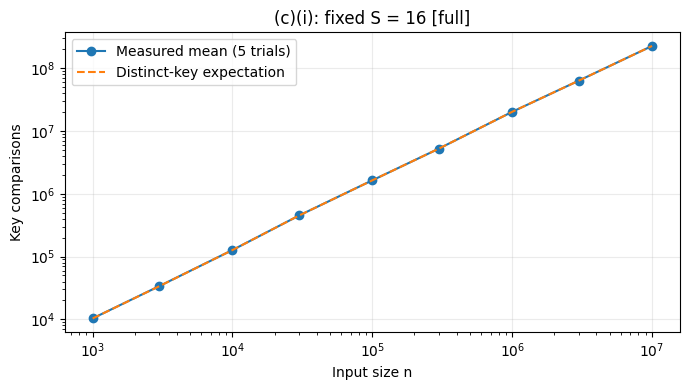

In [8]:
c1 = run_grid(C1_N, [("hybrid", FIXED_S)], "input_sizes")
c1_summary = summarize(c1).sort_values("n")
c1_summary.to_csv(RESULTS_DIR / "input_sizes.csv", index=False)

c1_analysis = c1_summary.copy()
c1_analysis["C_over_nlog2n"] = [
    row.mean_key_comparisons / (row.n * math.log2(row.n))
    for row in c1_analysis.itertuples()
]
display(c1_analysis)
c1_analysis.to_csv(RESULTS_DIR / "input_sizes_analysis.csv", index=False)

n_values = c1_summary["n"].tolist()
counts = c1_summary["mean_key_comparisons"].tolist()
model = [expected_comparisons(n, FIXED_S) for n in n_values]

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(n_values, counts, "o-", label=f"Measured mean ({REPEATS} trials)")
ax.loglog(n_values, model, "--", label="Distinct-key expectation")
ax.set(
    xlabel="Input size n", ylabel="Key comparisons",
    title=f"(c)(i): fixed S = {FIXED_S} [{MODE}]"
)
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "c1_comparisons_vs_n.png", dpi=160)
plt.show()
plt.close(fig)


**Interpretation of the saved run**

With S = 16, mean comparisons increase from 10,355.4 at n = 1,000 to 226,419,298.4 at n = 10,000,000. Across all nine tested sizes, C/(n log2 n) ranges from approximately 0.957 to 1.039; its value at the largest size is approximately 0.974. These observations are consistent with n log n growth over the measured range.

The measured means closely follow the distinct-key expectation curve. Variations arise from actual insertion-leaf sizes, random input variation, and duplicate values. The measurements support the theoretical analysis but do not by themselves prove an asymptotic bound or establish behavior for other input distributions.

#### 9. Fixed n, Varying S - Part (c)(ii)

This experiment fixes n = 100,000 and varies S from 1 through 64, with additional values 96 and 128. Each of the five trials shares its original input across all 66 thresholds.

Increasing S removes recursive divisions and merge levels while enlarging insertion-sort leaves. The terms in $O(nS+n\log_2(n/S))$ describe this tradeoff. Multiple thresholds can stop at identical leaves because recursive subarray sizes are discrete.

The plot compares measured comparisons with the distinct-key expectation. Ties in the generated data are not included in that model.

threshold_sweep: n=100,000, trial 1/5 finished


threshold_sweep: n=100,000, trial 2/5 finished


threshold_sweep: n=100,000, trial 3/5 finished


threshold_sweep: n=100,000, trial 4/5 finished


threshold_sweep: n=100,000, trial 5/5 finished


,experiment,algorithm,n,threshold,trials,mean_key_comparisons,median_cpu_seconds,min_cpu_seconds,max_cpu_seconds,median_wall_seconds
0,threshold_sweep,hybrid,100000,1,5,1536389.0,0.164062,0.156250,0.171875,0.168843
1,threshold_sweep,hybrid,100000,2,5,1536389.0,0.156250,0.156250,0.164062,0.162143
2,threshold_sweep,hybrid,100000,3,5,1536422.8,0.156250,0.125000,0.179688,0.153872
3,threshold_sweep,hybrid,100000,4,5,1536847.8,0.148438,0.140625,0.148438,0.149747
4,threshold_sweep,hybrid,100000,5,5,1536847.8,0.148438,0.148438,0.203125,0.151699
...,...,...,...,...,...,...,...,...,...,...
61,threshold_sweep,hybrid,100000,62,5,2381412.8,0.171875,0.156250,0.179688,0.175210
62,threshold_sweep,hybrid,100000,63,5,2381412.8,0.171875,0.156250,0.171875,0.168877
63,threshold_sweep,hybrid,100000,64,5,2381412.8,0.171875,0.156250,0.171875,0.168441
64,threshold_sweep,hybrid,100000,96,5,2381412.8,0.164062,0.164062,0.257812,0.168236


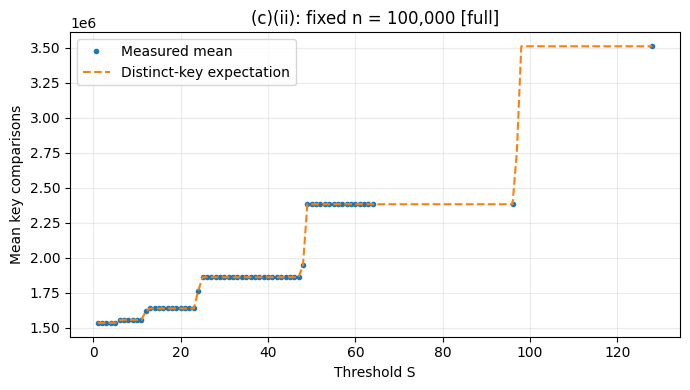

In [9]:
c2 = run_grid(
    [C2_N], [("hybrid", S) for S in SWEEP_S], "threshold_sweep"
)
c2_summary = summarize(c2).sort_values("threshold")
c2_summary.to_csv(RESULTS_DIR / "threshold_sweep.csv", index=False)
display(c2_summary)

model_thresholds = list(range(1, max(SWEEP_S) + 1))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    c2_summary["threshold"], c2_summary["mean_key_comparisons"],
    "o", markersize=3, label="Measured mean"
)
ax.plot(
    model_thresholds,
    [expected_comparisons(C2_N, S) for S in model_thresholds],
    "--", label="Distinct-key expectation"
)
ax.set(
    xlabel="Threshold S", ylabel="Mean key comparisons",
    title=f"(c)(ii): fixed n = {C2_N:,} [{MODE}]"
)
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "c2_comparisons_vs_s.png", dpi=160)
plt.show()
plt.close(fig)


**Interpretation of the saved run**

At n = 100,000, mean comparisons increase from 1,536,389.0 for S = 1 to 3,509,936.4 for S = 128. Intermediate means are 1,639,252.6 at S = 16 and 1,861,950.4 at S = 32. Extra insertion work can therefore exceed the comparison savings from fewer merge levels.

The curve contains plateaus. For example, S = 64 and S = 96 both give 2,381,412.8 mean comparisons because they stop at the same 48- or 49-element leaves. Comparison count alone does not determine runtime: recursive calls, allocations, and element movement also take time.

#### 10. Threshold Selection Across Sizes - Part (c)(iii)

Twelve candidate thresholds are measured at each of five tuning sizes: n = 1,000; 10,000; 100,000; 1,000,000; and 10,000,000. Each setting has five trials. The lowest median CPU time determines the winner for each size, with exact ties resolved by smaller S.

Each CPU time is divided by that size's median time at S = 1. Values below 1 indicate lower time than this baseline. Lines show normalized medians, and shading shows observed minimum-to-maximum ranges, not confidence intervals.

Timing variation matters when thresholds produce identical partitions or similar medians. Absolute measurements are retained in threshold_tuning.csv.

threshold_tuning: n=1,000, trial 1/5 restored from saved measurements
threshold_tuning: n=1,000, trial 2/5 restored from saved measurements
threshold_tuning: n=1,000, trial 3/5 restored from saved measurements
threshold_tuning: n=1,000, trial 4/5 restored from saved measurements
threshold_tuning: n=1,000, trial 5/5 restored from saved measurements
threshold_tuning: n=10,000, trial 1/5 restored from saved measurements
threshold_tuning: n=10,000, trial 2/5 restored from saved measurements
threshold_tuning: n=10,000, trial 3/5 restored from saved measurements
threshold_tuning: n=10,000, trial 4/5 restored from saved measurements
threshold_tuning: n=10,000, trial 5/5 restored from saved measurements
threshold_tuning: n=100,000, trial 1/5 restored from saved measurements
threshold_tuning: n=100,000, trial 2/5 restored from saved measurements
threshold_tuning: n=100,000, trial 3/5 restored from saved measurements
threshold_tuning: n=100,000, trial 4/5 restored from saved measurements
thresho

threshold_tuning: n=10,000,000, trial 5/5 finished


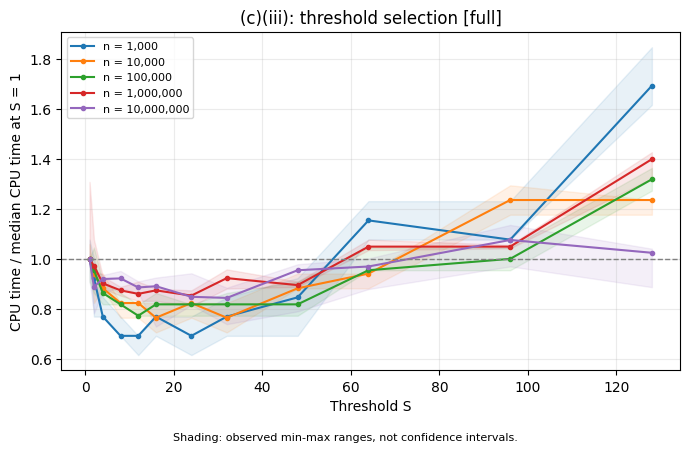

,experiment,algorithm,n,threshold,trials,mean_key_comparisons,median_cpu_seconds,min_cpu_seconds,max_cpu_seconds,median_wall_seconds
0,threshold_tuning,hybrid,1000,1,5,8703.4,0.001016,0.001016,0.001094,0.001027
1,threshold_tuning,hybrid,1000,2,5,8703.4,0.000937,0.000781,0.001016,0.000901
2,threshold_tuning,hybrid,1000,4,5,8759.4,0.000781,0.000781,0.000859,0.000799
3,threshold_tuning,hybrid,1000,8,5,9131.4,0.000703,0.000703,0.000781,0.000729
4,threshold_tuning,hybrid,1000,12,5,9131.4,0.000703,0.000625,0.000703,0.000714
5,threshold_tuning,hybrid,1000,16,5,10330.8,0.000781,0.000703,0.000781,0.000729
6,threshold_tuning,hybrid,1000,24,5,10330.8,0.000703,0.000625,0.000781,0.000760
7,threshold_tuning,hybrid,1000,32,5,13505.6,0.000781,0.000703,0.000859,0.000858
8,threshold_tuning,hybrid,1000,48,5,13505.6,0.000859,0.000703,0.000937,0.000845
9,threshold_tuning,hybrid,1000,64,5,20306.8,0.001172,0.001094,0.001250,0.001165


In [10]:
c3 = run_grid(
    C3_N, [("hybrid", S) for S in TUNING_S], "threshold_tuning"
)
c3_summary = summarize(c3)
c3_summary.to_csv(RESULTS_DIR / "threshold_tuning.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
for n, group in c3_summary.groupby("n"):
    group = group.sort_values("threshold")
    baseline = float(
        group.loc[group["threshold"] == 1, "median_cpu_seconds"].iloc[0]
    )
    if baseline <= 0:
        raise ValueError("The S=1 CPU baseline must be positive.")
    line, = ax.plot(
        group["threshold"], group["median_cpu_seconds"] / baseline,
        "o-", markersize=3, label=f"n = {n:,}"
    )
    ax.fill_between(
        group["threshold"].to_numpy(dtype=float),
        group["min_cpu_seconds"].to_numpy(dtype=float) / baseline,
        group["max_cpu_seconds"].to_numpy(dtype=float) / baseline,
        color=line.get_color(), alpha=0.10
    )
ax.axhline(1, linestyle="--", color="gray", linewidth=1)
ax.set(
    xlabel="Threshold S", ylabel="CPU time / median CPU time at S = 1",
    title=f"(c)(iii): threshold selection [{MODE}]"
)
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)
fig.text(
    0.5, 0.01, "Shading: observed min-max ranges, not confidence intervals.",
    ha="center", fontsize=8
)
fig.tight_layout(rect=(0, 0.035, 1, 1))
fig.savefig(FIGURES_DIR / "c3_threshold_cpu.png", dpi=160)
plt.show()
plt.close(fig)
display(c3_summary)


**Threshold selection**

For each input size, candidates are ordered by median CPU time and then by S. The winner at the largest tuning size supplies the threshold for the final comparison.

This selects the best measured candidate for the current input distribution and execution environment. It does not establish a unique or universal optimum.

In [11]:
# Sort by the selection criterion, then keep one winner per input size.
best_by_n = (
    c3_summary.sort_values(["n", "median_cpu_seconds", "threshold"])
    .drop_duplicates(subset="n", keep="first")
    [["n", "threshold", "median_cpu_seconds", "mean_key_comparisons"]]
    .rename(columns={"threshold": "best_threshold"})
    .sort_values("n")
)
best_by_n.to_csv(RESULTS_DIR / "best_threshold.csv", index=False)
display(best_by_n)

selection_n = int(best_by_n.iloc[-1]["n"])
best_S = int(best_by_n.iloc[-1]["best_threshold"])
if best_S == max(TUNING_S):
    print("The winner is at the upper search boundary; interpret it as the best tested S.")

selection_record = {
    "mode": MODE,
    "selection_n": selection_n,
    "candidate_thresholds": TUNING_S,
    "selected_threshold": best_S,
    "criterion": "minimum median CPU time; exact ties use smaller S",
}
with (RESULTS_DIR / "selected_threshold.json").open("w", encoding="utf-8") as file:
    json.dump(selection_record, file, indent=2)

print(f"Selected S = {best_S} from n = {selection_n:,}.")
print("The threshold minimizes the measured median CPU time at this input size.")


,n,best_threshold,median_cpu_seconds,mean_key_comparisons
3,1000,8,0.000703,9131.4
17,10000,16,0.010156,127046.2
28,100000,12,0.132812,1619860.4
42,1000000,24,1.906250,20224685.4
55,10000000,32,32.437500,242320327.2


Selected S = 32 from n = 10,000,000.
The threshold minimizes the measured median CPU time at this input size.


**Interpretation of the saved run**

The selected candidates are S = 8, 16, 12, 24, and 32 for n = 1,000; 10,000; 100,000; 1,000,000; and 10,000,000, respectively. Their median CPU times are 0.000703125, 0.01015625, 0.1328125, 1.90625, and 32.4375 seconds. S = 32 is selected for the final comparison because it wins at the largest tuning size.

At n = 10,000,000, S = 24 and S = 32 produce the same 19- or 20-element leaves and the same mean comparison count, 242,320,327.2. Their median CPU times are very close: 32.609375 and 32.4375 seconds, respectively. Their observed ranges overlap (31.34375-36.21875 versus 28.40625-34.0 seconds). The selected threshold is a measured candidate, not a precisely established unique optimum.

The fastest configuration does not minimize comparisons: at n = 10,000,000, S = 1 uses 220,100,460.8 mean comparisons but has a higher CPU-time median of 38.4375 seconds. Rankings depend on implementation overhead, input distribution, actual leaf sizes, and timing variation; there is no single measured threshold that wins at every tested size.

#### 11. Original Merge Sort versus Hybrid - Part (d)

The final experiment compares merge sort with the hybrid using the selected threshold and fresh seeds. Both algorithms receive identical input within each trial. Odd trials run the hybrid first; even trials run merge sort first.

The saved full run uses 10,000,000 integers over five trials, with S = 32 for the hybrid. The new seeds are 520260914 through 520260918; none was used for threshold tuning. Tables report comparison counts, CPU times, elapsed times, and paired outcomes.

CPU-time reduction is (merge median - hybrid median) / merge median. Comparison-count change is (hybrid mean - merge mean) / merge mean; a positive value means the hybrid performs more comparisons.

In [12]:
d_results = run_grid(
    [COMPARISON_N], [("merge", 1), ("hybrid", best_S)],
    "merge_comparison"
)
d_summary = summarize(d_results)

# Show the merge-sort baseline before the hybrid result.
d_summary = (
    d_summary.assign(order=d_summary["algorithm"].map({"merge": 0, "hybrid": 1}))
    .sort_values("order")
    .drop(columns="order")
)
d_summary.to_csv(RESULTS_DIR / "merge_comparison.csv", index=False)
display(d_summary)

merge_row = d_summary.loc[d_summary["algorithm"] == "merge"].iloc[0]
hybrid_row = d_summary.loc[d_summary["algorithm"] == "hybrid"].iloc[0]

time_reduction = (
    merge_row["median_cpu_seconds"] - hybrid_row["median_cpu_seconds"]
) / merge_row["median_cpu_seconds"]
comparison_change = (
    hybrid_row["mean_key_comparisons"] - merge_row["mean_key_comparisons"]
) / merge_row["mean_key_comparisons"]
speedup = merge_row["median_cpu_seconds"] / hybrid_row["median_cpu_seconds"]

# Show paired outcomes as well as the ratio of the two medians.
paired_cpu = d_results.pivot(
    index=["trial", "seed"], columns="algorithm", values="cpu_seconds"
).reset_index()
paired_cpu["hybrid_faster"] = paired_cpu["hybrid"] < paired_cpu["merge"]
paired_cpu.to_csv(RESULTS_DIR / "merge_comparison_paired.csv", index=False)
display(paired_cpu)

assert len(RUN_RECORDS) == expected_records
print(f"Recorded {len(RUN_RECORDS)} measurements in {MODE} mode.")
print(f"Comparison input size: {COMPARISON_N:,}; selected S: {best_S}")
print(f"CPU time reduction: {time_reduction:.2%}")
print(f"Comparison count change (hybrid versus merge): {comparison_change:+.2%}")
print(f"Speedup (merge / hybrid): {speedup:.3f}x")
print(f"Hybrid faster in {int(paired_cpu['hybrid_faster'].sum())}/{REPEATS} paired trials.")
if not FULL_RUN:
    print("Quick comparison only: full part (d) requires n = 10,000,000.")

settings["selected_threshold"] = best_S
settings["measurement_records"] = len(RUN_RECORDS)
with (RESULTS_DIR / "settings.json").open("w", encoding="utf-8") as file:
    json.dump(settings, file, indent=2)


merge_comparison: n=10,000,000, trial 1/5 finished


merge_comparison: n=10,000,000, trial 2/5 finished


merge_comparison: n=10,000,000, trial 3/5 finished


merge_comparison: n=10,000,000, trial 4/5 finished


merge_comparison: n=10,000,000, trial 5/5 finished


,experiment,algorithm,n,threshold,trials,mean_key_comparisons,median_cpu_seconds,min_cpu_seconds,max_cpu_seconds,median_wall_seconds
1,merge_comparison,merge,10000000,1,5,220101680.0,36.12500,35.453125,40.609375,36.658979
0,merge_comparison,hybrid,10000000,32,5,242316014.8,32.40625,32.203125,36.328125,32.851283


algorithm,trial,seed,hybrid,merge,hybrid_faster
0,1,520260914,36.328125,36.125000,False
1,2,520260915,32.203125,35.640625,True
2,3,520260916,32.406250,35.453125,True
3,4,520260917,33.406250,36.328125,True
4,5,520260918,32.296875,40.609375,True


Recorded 685 measurements in full mode.
Comparison input size: 10,000,000; selected S: 32
CPU time reduction: 10.29%
Comparison count change (hybrid versus merge): +10.09%
Speedup (merge / hybrid): 1.115x
Hybrid faster in 4/5 paired trials.


#### 12. Discussion and Conclusion

The saved Python run contains 685 full-mode measurement records: 45 for fixed-S size scaling, 330 for the fixed-n threshold sweep, 300 for threshold tuning, and 10 for the final algorithm comparison. It covers inputs up to 10,000,000 integers with five trials per setting. Every recorded sorting result was checked against Python's sorted function; all correctness and comparison-count tests passed.

For fixed S = 16, comparison counts are consistent with n log n growth across the tested sizes. Increasing S eventually increases comparisons because insertion-sort leaves require more work. Plateaus occur when several thresholds lead to the same partitions.

Threshold tuning selected S = 32 at n = 10,000,000. On fresh inputs of that size, merge sort used 220,101,680.0 key comparisons on average, while the hybrid used 242,316,014.8, an increase of 10.09%.

The recorded median CPU times were 36.125 seconds for merge sort and 32.40625 seconds for the hybrid. This is a 10.29% reduction and a 1.115x speedup. The hybrid was faster in four of the five paired trials and slightly slower in the first trial (36.328125 versus 36.125 seconds).

Observed CPU times ranged from 35.453125 to 40.609375 seconds for merge sort and from 32.203125 to 36.328125 seconds for the hybrid. Median elapsed times were approximately 36.659 and 32.851 seconds, respectively. The improvement in median CPU time does not imply that every individual hybrid run is faster.

These results are consistent with reduced recursion and merging overhead offsetting extra insertion comparisons, although timing does not isolate individual operation costs. The findings apply to the current Python implementation, input distribution, tested sizes, and runtime environment.

**Limitations and reproducibility**

List slicing and merged-result allocation occur during sorting. Comparison counting and timing-loop overhead are included in CPU measurements. Short sorts are batched to reduce timer-resolution effects, but variation remains; minimum-to-maximum ranges are not confidence intervals.

Measurements span two execution sessions because the run was resumed after an interruption. The first 663 records were retained exactly and only the remaining 22 were measured after resuming; all final paired comparisons were collected in the second session. This session boundary and ordinary timing variation limit fine-grained threshold rankings. Five trials on one environment do not establish statistical significance or a universal optimal S.

Each run saves configuration and environment information, seeds, raw measurements, summaries, and three figures. The main data files are raw_measurements.csv, input_sizes.csv, threshold_sweep.csv, threshold_tuning.csv, best_threshold.csv, and merge_comparison.csv. The timed_sorts field identifies records that average multiple short sorts.